In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import joblib

In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/simtoor/mall-customers/Mall Customers.xlsx


In [3]:
import pandas as pd

df = pd.read_excel('/kaggle/input/datasets/simtoor/mall-customers/Mall Customers.xlsx')

print(df.shape)
display(df.head())

(200, 7)


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nStatistical summary:")
display(df.describe(include='all'))

Dataset shape: (200, 7)

Column names:
['CustomerID', 'Gender', 'Age', 'Education ', 'Marital Status', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Education               200 non-null    object
 4   Marital Status          200 non-null    object
 5   Annual Income (k$)      200 non-null    int64 
 6   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(3)
memory usage: 11.1+ KB

First five rows:


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,Married,15,39
1,2,M,21,Graduate,Single,15,81
2,3,F,20,Graduate,Married,16,6
3,4,F,23,High School,Unknown,16,77
4,5,F,31,Uneducated,Married,17,40



Statistical summary:


,CustomerID,Gender,Age,Education,Marital Status,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200,200,200.000000,200.000000
unique,NaN,2,NaN,7,4,NaN,NaN
top,NaN,F,NaN,Graduate,Married,NaN,NaN
freq,NaN,112,NaN,67,112,NaN,NaN
mean,100.500000,NaN,38.850000,NaN,NaN,60.560000,50.200000
std,57.879185,NaN,13.969007,NaN,NaN,26.264721,25.823522
min,1.000000,NaN,18.000000,NaN,NaN,15.000000,1.000000
25%,50.750000,NaN,28.750000,NaN,NaN,41.500000,34.750000
50%,100.500000,NaN,36.000000,NaN,NaN,61.500000,50.000000
75%,150.250000,NaN,49.000000,NaN,NaN,78.000000,73.000000


In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Missing values:
CustomerID                0
Gender                    0
Age                       0
Education                 0
Marital Status            0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0

Data types:
CustomerID                 int64
Gender                    object
Age                        int64
Education                 object
Marital Status            object
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


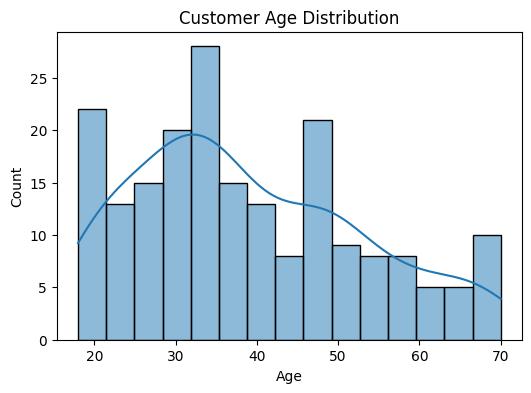

In [6]:
plt.figure(figsize=(6, 4))
sns.histplot(df['Age'], bins=15, kde=True)
plt.title('Customer Age Distribution')
plt.show()

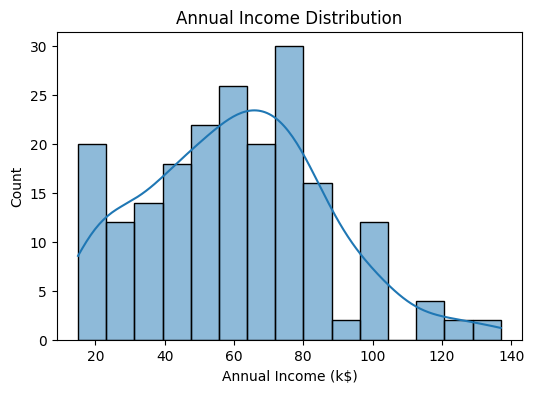

In [7]:
plt.figure(figsize=(6, 4))
sns.histplot(df['Annual Income (k$)'], bins=15, kde=True)
plt.title('Annual Income Distribution')
plt.show()

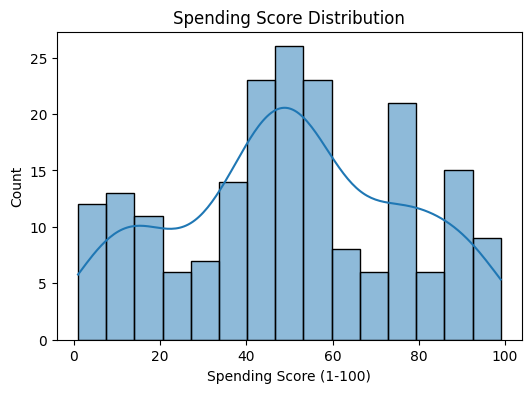

In [8]:
plt.figure(figsize=(6, 4))
sns.histplot(df['Spending Score (1-100)'], bins=15, kde=True)
plt.title('Spending Score Distribution')
plt.show()

In [9]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print(X.head())
print("\nSelected features:", X.columns.tolist())

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Selected features: ['Annual Income (k$)', 'Spending Score (1-100)']


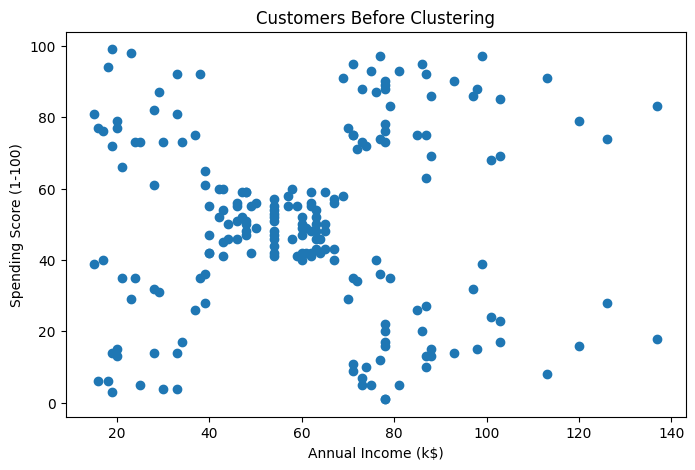

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)']
)

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customers Before Clustering')

plt.show()

In [11]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


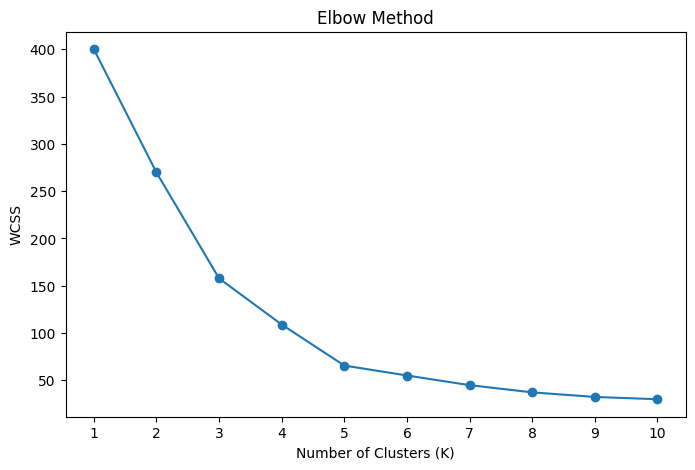

In [12]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')

plt.xticks(range(1, 11))
plt.show()

In [13]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

print("K-Means model trained successfully!")

K-Means model trained successfully!


In [14]:
df['Cluster'] = kmeans.labels_

display(
    df[['Annual Income (k$)','Spending Score (1-100)','Cluster']].head(10)
)

,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4
5,17,76,2
6,18,6,4
7,18,94,2
8,19,3,4
9,19,72,2


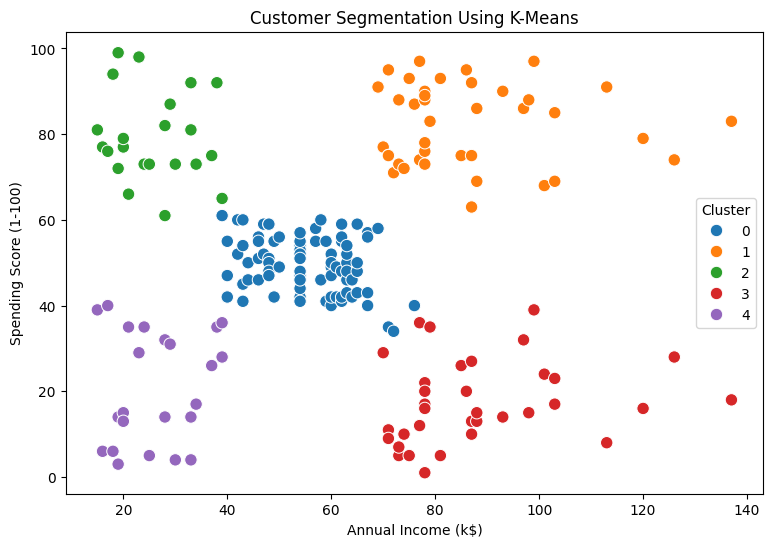

In [15]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='tab10',
    s=80
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.show()

In [16]:
score = silhouette_score(X_scaled, kmeans.labels_)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.555


In [17]:
cluster_summary = df.groupby('Cluster').agg(
    Customer_Count=('Cluster', 'count'),
    Average_Income=('Annual Income (k$)', 'mean'),
    Average_Spending_Score=('Spending Score (1-100)', 'mean')
).round(2)

display(cluster_summary)

,Customer_Count,Average_Income,Average_Spending_Score
Cluster,,,
0,81,55.30,49.52
1,39,86.54,82.13
2,22,25.73,79.36
3,35,88.20,17.11
4,23,26.30,20.91


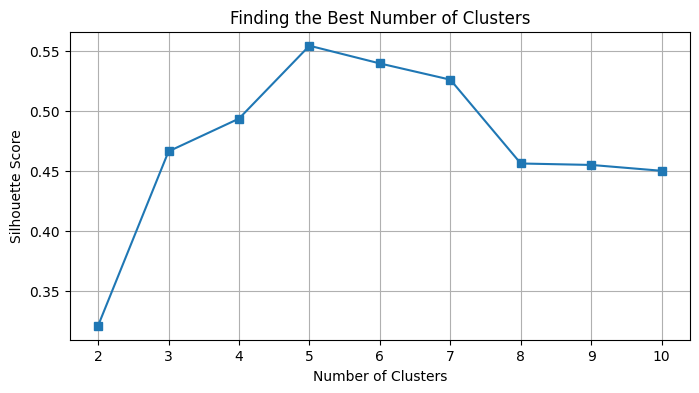

Best cluster count: 5


In [18]:
cluster_counts = list(range(2, 11))
silhouette_scores = []

for count in cluster_counts:
    model = KMeans(
        n_clusters=count,
        random_state=21,
        n_init=15
    )

    predicted_groups = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, predicted_groups)

    silhouette_scores.append(score)

plt.figure(figsize=(8, 4))
plt.plot(cluster_counts, silhouette_scores, marker="s")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Finding the Best Number of Clusters")
plt.grid(True)
plt.show()

optimal_k = cluster_counts[silhouette_scores.index(max(silhouette_scores))]
print("Best cluster count:", optimal_k)

In [19]:
df["Customer_Group"] = kmeans.labels_

summary = df.groupby("Customer_Group").agg({
    "Age": "mean",
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean",
    "Customer_Group": "count"
}).round(2)

summary = summary.rename(columns={
    "Age": "Mean_Age",
    "Annual Income (k$)": "Mean_Income",
    "Spending Score (1-100)": "Mean_Spending",
    "Customer_Group": "Total_Customers"
})

display(summary)

,Mean_Age,Mean_Income,Mean_Spending,Total_Customers
Customer_Group,,,,
0,42.72,55.30,49.52,81
1,32.69,86.54,82.13,39
2,25.27,25.73,79.36,22
3,41.11,88.20,17.11,35
4,45.22,26.30,20.91,23


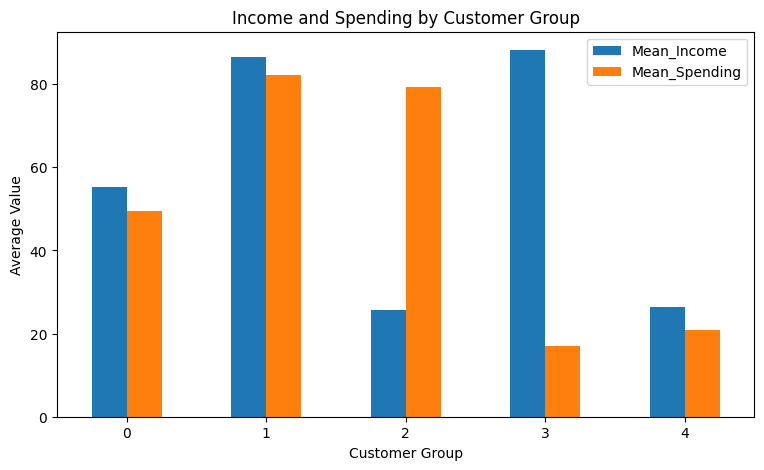

In [20]:
summary[["Mean_Income", "Mean_Spending"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Income and Spending by Customer Group")
plt.xlabel("Customer Group")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.show()

In [21]:
from sklearn.model_selection import train_test_split

features = df[[
    "Annual Income (k$)",
    "Spending Score (1-100)"
]]

target = df["Customer_Group"]

X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.25,
    random_state=42,
    stratify=target
)

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42,
        eval_metric="mlogloss"
    )
}

model_scores = []

for model_name, classifier in classifiers.items():
    classifier.fit(X_train, y_train)
    output = classifier.predict(X_test)

    model_scores.append({
        "Algorithm": model_name,
        "Accuracy": accuracy_score(y_test, output),
        "Macro F1": f1_score(y_test, output, average="macro")
    })

score_table = pd.DataFrame(model_scores)
display(score_table.sort_values("Macro F1", ascending=False).round(3))

,Algorithm,Accuracy,Macro F1
0,Logistic Regression,1.00,1.000
1,Random Forest,0.98,0.973
3,XGBoost,0.96,0.958
2,AdaBoost,0.94,0.918


In [23]:
import os
import joblib
import shutil

os.makedirs('/kaggle/working/customer_segmentation', exist_ok=True)

joblib.dump(
    scaler,
    '/kaggle/working/customer_segmentation/scaler.pkl'
)

joblib.dump(
    kmeans,
    '/kaggle/working/customer_segmentation/kmeans_model.pkl'
)

shutil.make_archive(
    '/kaggle/working/customer_segmentation',
    'zip',
    '/kaggle/working/customer_segmentation'
)

print("Model files saved successfully!")

Model files saved successfully!
